# Load Database and creat its table to pandas data frame

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3
import warnings

conn = sqlite3.connect("customer_churn.db")

sql_query = """
SELECT name  
FROM sqlite_master  
WHERE type='table';
"""

tables = pd.read_sql(sql_query, conn)

for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn)
    globals()[f"df_{table_name}"] = df
    print(f"Created dataframe: df_{table_name}")
    
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [2]:
conn = sqlite3.connect("customer_churn.db")

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

conn.close()


Table Name: db_customer
Columns:
['customerid', 'name', 'country', 'state', 'gender', 'dob', 'interests', 'pincode']

Table Name: db_subscription
Columns:
['customerid', 'subscription_start_date', 'subscription_type', 'renewal_date', 'plan_type', 'contract_type', 'cancellation_date', 'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score']

Table Name: db_support
Columns:
['customerid', 'complaint_date', 'escalations', 'csat_score', 'col_1', 'comment']


# Data cleaning

In [3]:
# df_db_customer.head()
df_db_customer.tail()

,customerid,name,country,state,gender,dob,interests,pincode
495,0519-KTXFC,madan,India,Nagaland,Male,1979-11-25 00:00:00,gaming,None
496,0520-BLFPE,maya,India,Rajasthan,Female,1979-01-27 00:00:00,NaN,None
497,0521-AOHCM,rangadevi,India,Meghalaya,Women,1998-08-14 00:00:00,NaN,None
498,0522-XPOFK,rani,India,Haryana,Women,1970-08-26 00:00:00,NaN,None
499,0523-TGIPX,ajay,NaN,Kathmandu,Male,1991-02-11 00:00:00,NaN,None


In [4]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   customerid  500 non-null    str   
 1   name        500 non-null    str   
 2   country     408 non-null    str   
 3   state       500 non-null    str   
 4   gender      500 non-null    str   
 5   dob         500 non-null    str   
 6   interests   101 non-null    str   
 7   pincode     0 non-null      object
dtypes: object(1), str(7)
memory usage: 31.4+ KB


In [5]:
# Rename the column
df_db_customer.rename(columns = {"name" : "customer_name"}, inplace = True)

In [6]:
# Drop two column interests, picode
df_db_customer.drop(columns = ["interests", "pincode"], inplace = True)

In [7]:
# Change column data type
df_db_customer["dob"] = pd.to_datetime(df_db_customer["dob"])

In [8]:
df_db_customer["gender"].unique()

<StringArray>
['Male', 'Female', 'Women', 'Men']
Length: 4, dtype: str

In [9]:
# Fix the column category
df_db_customer.loc[df_db_customer["gender"] == "Men", "gender"] = "Male"
df_db_customer.loc[df_db_customer["gender"] == "Women", "gender"] = "Female"

In [10]:
df_db_customer["gender"].unique()

<StringArray>
['Male', 'Female']
Length: 2, dtype: str

In [11]:
df_db_customer["customer_name"] = df_db_customer["customer_name"].str.lower()

In [12]:
df_db_customer[df_db_customer["country"].isna()]

,customerid,customer_name,country,state,gender,dob
5,0013-MHZWF,durga,NaN,Delhi,Female,1988-12-10
8,0015-UOCOJ,maya,NaN,Kathmandu,Female,1985-07-07
12,0018-NYROU,chitra,NaN,Telangana,Female,2004-12-01
21,0045-QAHFT,karan,NaN,Pokhara,Male,1997-01-02
25,0049-QJJFG,dev,NaN,Nagaland,Male,1987-01-08
...,...,...,...,...,...,...
483,0507-RHKCR,durga,NaN,Nagaland,Female,1978-08-30
489,0513-EGPDU,shruti,NaN,Karnataka,Female,1978-01-18
491,0515-ERPSP,nikhil,NaN,Telangana,Male,1980-07-27
492,0516-ZZQWZ,suresh,NaN,Meghalaya,Male,1975-01-21


In [13]:
# Filling the Nan value
country_maping = df_db_customer.dropna(subset = "country").set_index("state")["country"].to_dict()  
df_db_customer["country"] = df_db_customer["country"].fillna(df_db_customer["state"].map(country_maping))

In [14]:
df_db_customer["country"].isna().sum()

np.int64(0)

In [15]:
df_db_customer.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   customerid     500 non-null    str           
 1   customer_name  500 non-null    str           
 2   country        500 non-null    str           
 3   state          500 non-null    str           
 4   gender         500 non-null    str           
 5   dob            500 non-null    datetime64[us]
dtypes: datetime64[us](1), str(5)
memory usage: 23.6 KB


In [16]:
# df_db_subscription.head()
df_db_subscription.tail()

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
495,0519-KTXFC,2020-01-26,Organic,2025-01-26,Premium,Monthly,2021-05-20,Forgot to cancel trial,22.99,1221,95
496,0520-BLFPE,2019-08-14,Referral,2023-08-14,Basic,Annual,NaN,NaN,16.99,706,40
497,0521-AOHCM,2020-09-13,Paid,2021-09-13,Basic,Annual,2021-07-14,Moving away,6.99,257,88
498,0522-XPOFK,2021-09-27,Organic,2025-09-27,Standard,Monthly,2022-03-02,Not enough content,13.99,2096,98
499,0523-TGIPX,2022-09-24,Referral,2026-09-24,Standard,Annual,2023-04-28,Poor streaming quality,7.99,1231,88


In [17]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               500 non-null    str    
 1   subscription_start_date  500 non-null    str    
 2   subscription_type        500 non-null    str    
 3   renewal_date             500 non-null    str    
 4   plan_type                500 non-null    str    
 5   contract_type            500 non-null    str    
 6   cancellation_date        146 non-null    str    
 7   cancellation_reason      146 non-null    str    
 8   monthly_charges          500 non-null    float64
 9   cltv                     500 non-null    int64  
 10  churn_score              500 non-null    int64  
dtypes: float64(1), int64(2), str(8)
memory usage: 43.1 KB


In [18]:
# Change column data type
date_column = df_db_subscription[["subscription_start_date", "renewal_date", "cancellation_date"]].apply(pd.to_datetime) 
df_db_subscription[["subscription_start_date", "renewal_date", "cancellation_date"]] = date_column

In [19]:
df_db_subscription["subscription_type"].unique()

<StringArray>
['Refferal', 'Paid', 'Organic', 'Referral']
Length: 4, dtype: str

In [20]:
df_db_subscription["subscription_type"] = df_db_subscription["subscription_type"].replace("Refferal", "Referral")

In [21]:
df_db_subscription["subscription_type"].unique()

<StringArray>
['Referral', 'Paid', 'Organic']
Length: 3, dtype: str

In [22]:
df_db_subscription.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   customerid               500 non-null    str           
 1   subscription_start_date  500 non-null    datetime64[us]
 2   subscription_type        500 non-null    str           
 3   renewal_date             500 non-null    datetime64[us]
 4   plan_type                500 non-null    str           
 5   contract_type            500 non-null    str           
 6   cancellation_date        146 non-null    datetime64[us]
 7   cancellation_reason      146 non-null    str           
 8   monthly_charges          500 non-null    float64       
 9   cltv                     500 non-null    int64         
 10  churn_score              500 non-null    int64         
dtypes: datetime64[us](3), float64(1), int64(2), str(5)
memory usage: 43.1 KB


In [23]:
# df_db_support.head()
df_db_support.tail()

,customerid,complaint_date,escalations,csat_score,col_1,comment
145,0170-ICRHP,2024-03-11 00:00:00,N,90,None,NaN
146,0180-NNEYE,2024-08-28 00:00:00,Y,20,None,NaN
147,0146-ZEYLR,2024-11-21 00:00:00,N,60,None,NaN
148,0046-SSKLH,2024-08-10 00:00:00,Y,20,None,NaN
149,0046-SSKLH,2024-08-11 00:00:00,N,20,None,NaN


In [24]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   customerid      150 non-null    str   
 1   complaint_date  150 non-null    str   
 2   escalations     150 non-null    str   
 3   csat_score      150 non-null    int64 
 4   col_1           0 non-null      object
 5   comment         67 non-null     str   
dtypes: int64(1), object(1), str(4)
memory usage: 7.2+ KB


In [25]:
# Drop last two column
df_db_support.drop(df_db_support.columns[-2:], axis = 1, inplace = True)

In [26]:
# Change column data type
df_db_support["complaint_date"] = pd.to_datetime(df_db_support["complaint_date"])

In [27]:
df_db_support.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   customerid      150 non-null    str           
 1   complaint_date  150 non-null    datetime64[us]
 2   escalations     150 non-null    str           
 3   csat_score      150 non-null    int64         
dtypes: datetime64[us](1), int64(1), str(2)
memory usage: 4.8 KB


# Feature engineering

In [28]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34


In [29]:
df_db_subscription["churn_flag"] = np.where(df_db_subscription["cancellation_date"].notna(), 1, 0)

In [30]:
df_db_subscription.head(3)

,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score,churn_flag
0,0002-ORFBO,2021-03-15,Referral,2025-03-15,Standard,Annual,NaT,NaN,13.99,627,12,0
1,0003-MKNFE,2020-08-01,Paid,2024-08-01,Premium,Annual,2024-09-10,Switched to competitor,12.99,1150,91,1
2,0004-TLHLJ,2022-11-20,Organic,2025-11-20,Basic,Monthly,NaT,NaN,6.99,210,34,0


In [31]:
df_db_subscription.shape

(500, 12)

In [32]:
df_db_customer.shape

(500, 6)

In [33]:
df_db_support.shape

(150, 4)

In [34]:
df_db_subscription["customerid"].nunique()

500

In [35]:
df_db_customer["customerid"].nunique()

500

In [36]:
df_db_support["customerid"].nunique()

107

In [37]:
df_db_support["customerid"].size

150

In [38]:
df_db_support["complain_count"] = df_db_support.groupby("customerid")["customerid"].transform("count")

In [39]:
df_db_support = df_db_support.sort_values('complaint_date').drop_duplicates("customerid", keep = "last")

In [40]:
df_db_support["customerid"].size

107

In [41]:
df = (df_db_subscription.merge(df_db_customer, how = "left", on = "customerid").merge(df_db_support, how = "left", on = "customerid"))

In [42]:
df.shape

(500, 21)

# Data analysis

In [43]:
df.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complain_count'],
      dtype='str')

In [44]:
# churn rate
churn_rate = round(df["churn_flag"].mean()*100, 2)
print("churn rate :", churn_rate, "%")

churn rate : 29.2 %


In [45]:
# retention rate 
retention_rate = 100 - churn_rate
print("retention rate :", retention_rate, "%")

retention rate : 70.8 %


In [46]:
# churn rate by plane type
churn_rate_by_plan = df.groupby("plan_type")["churn_flag"].mean().mul(100).round(2).reset_index(name = "churn_rate_pct")
churn_rate_by_plan

,plan_type,churn_rate_pct
0,Basic,32.48
1,Premium,31.37
2,Standard,26.09


In [47]:
today = pd.Timestamp.today()
df["tenure_days"] = np.where(
    df["cancellation_date"].isna(),
    (today - df["subscription_start_date"]).dt.days,
    (df["cancellation_date"] - df["subscription_start_date"]).dt.days
)

In [48]:
#avg customer tenure
avg_tenure = round(df["tenure_days"].mean(), 2)
print("avg tenure (Days):", avg_tenure)

avg tenure (Days): 1507.2


In [49]:
# revenue risk - revenue lost from churn user
revenue_risk = df.loc[df["churn_flag"] == 1, "monthly_charges"].sum()
print("revenue_at_risk (Rs 'k'):", revenue_risk)

revenue_at_risk (Rs 'k'): 2218.54


In [50]:
# Escalation Rate
Escalation_rate = round((df["escalations"] == "Y").mean() * 100, 2)
print("Escalation rate : ", Escalation_rate, "%")

Escalation rate :  12.6 %


In [51]:
# avg complaints per user
avg_complaints = round(df["complain_count"].sum()/df["customerid"].nunique(), 2)
print("Avg complaints per user :", avg_complaints)

Avg complaints per user : 0.3


In [52]:
# Correlation escalation vs churn
temp_df = df[["escalations", "churn_flag"]].dropna()
temp_df["escalations"] = np.where(temp_df["escalations"] == "Y", 1, 0)
Correlation = round(temp_df["escalations"].corr(df["churn_flag"]), 2)
print("Correlation between escalation vs churn is :", Correlation)

Correlation between escalation vs churn is : 0.04


In [53]:
# creat a col using existing col - churn risk
df["churn_risk"] = np.where(
    df["churn_score"] >= 70, "High", np.where(
        df["churn_score"] >= 50, "Medium", "Low"
    )
)

In [54]:
# "Calculate the sum of monthly charges, unique count of customer ID, and average of churn flag for each plan type."
pd.pivot_table(
    df,
    index = "plan_type",
    values = ["monthly_charges", "customerid", "churn_flag"],
    aggfunc = {
        "monthly_charges" : "sum",
        "customerid" : "nunique",
        "churn_flag" : "mean"
    }
).reset_index()

,plan_type,churn_flag,customerid,monthly_charges
0,Basic,0.324786,117,1228.83
1,Premium,0.313725,153,3753.47
2,Standard,0.260870,230,3007.70


# Visualization using matplotlib & seaborn

In [55]:
# First matplotlib

In [56]:
df_visual = df.copy()

In [57]:
df_visual.columns

Index(['customerid', 'subscription_start_date', 'subscription_type',
       'renewal_date', 'plan_type', 'contract_type', 'cancellation_date',
       'cancellation_reason', 'monthly_charges', 'cltv', 'churn_score',
       'churn_flag', 'customer_name', 'country', 'state', 'gender', 'dob',
       'complaint_date', 'escalations', 'csat_score', 'complain_count',
       'tenure_days', 'churn_risk'],
      dtype='str')

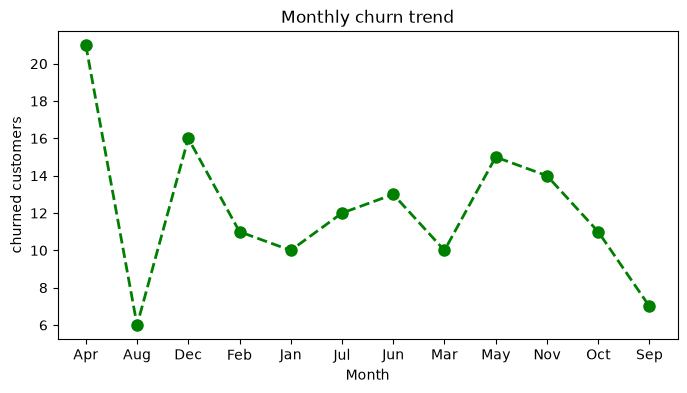

In [58]:
# Line plot
# Monthly churn trend (Time series KPI)
df_visual["cancellation_month"] = df_visual["cancellation_date"].dt.strftime("%b")
churn_trend = df_visual[df_visual["churn_flag"] == 1].groupby("cancellation_month").size()

plt.figure(figsize = (8,4))
plt.plot(churn_trend.index, churn_trend.values , color = "green", marker = "o", linestyle = "--", linewidth = 2, markersize = 8)
plt.title("Monthly churn trend")
plt.xlabel("Month")
plt.ylabel("churned customers")
plt.show()

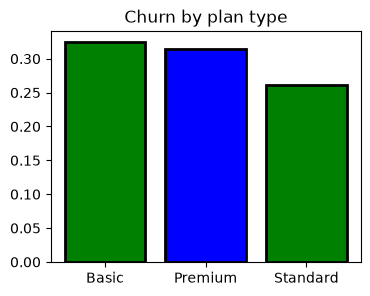

In [59]:
# Bar plot
# Churn by plan type
churn_by_plan = df_visual.groupby("plan_type")["churn_flag"].mean()

plt.figure(figsize = (4,3))
plt.bar(churn_by_plan.index, churn_by_plan.values, color = ["green", "blue"], edgecolor = "black", linewidth = 2)
plt.title("Churn by plan type")
plt.show()

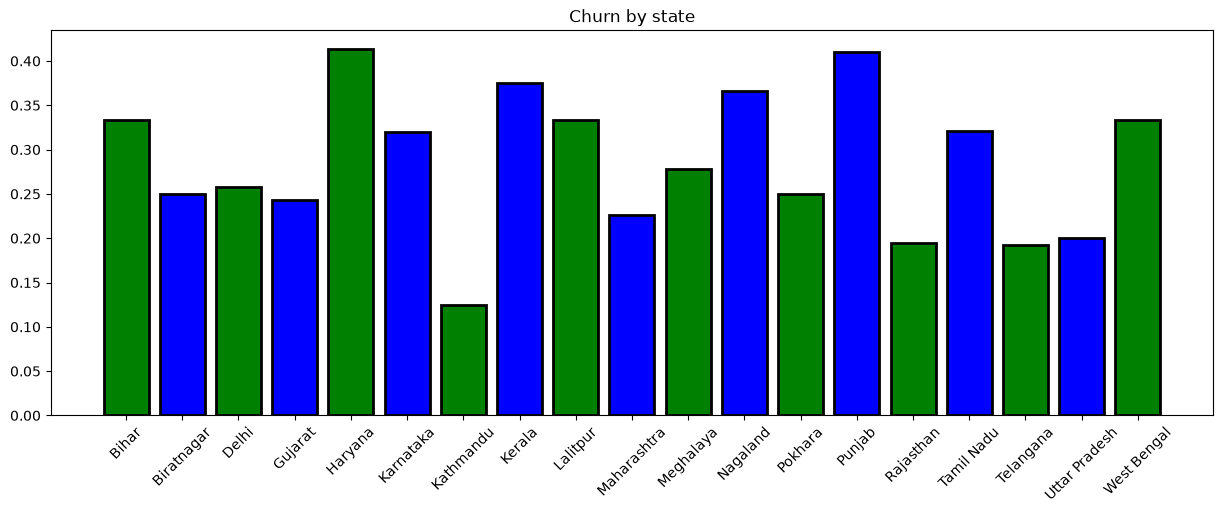

In [60]:
# # Bar plot
# Churn by state
churn_by_state = df_visual.groupby("state")["churn_flag"].mean()

plt.figure(figsize = (15,5))
plt.bar(churn_by_state.index, churn_by_state.values, color = ["green", "blue"], edgecolor = "black", linewidth = 2)
plt.title("Churn by state")
plt.xticks(rotation = 45)
plt.show()

In [61]:
# Second seaborn

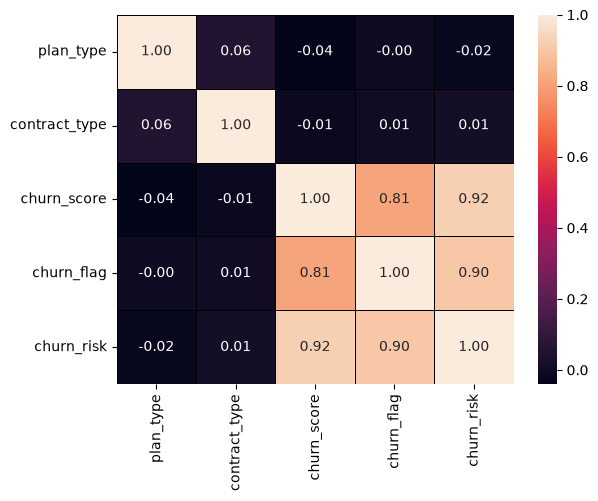

In [62]:
# Heatmap
# Correlation in ['plan_type', 'contract_type','churn_score', 'churn_flag', 'churn_risk']
df_encoded = df_visual[['plan_type', 'contract_type','churn_score', 'churn_flag', 'churn_risk']]
warnings.filterwarnings("ignore")
order_mappings = {
    "plan_type" : ["Basic", "Standard", "Premium"],
    "contract_type" : ["Monthly", "Annual"],
    "churn_risk" : ["Low", "Medium", "High"]
}
for col, order in order_mappings.items() :
    df_encoded[col] = pd.Categorical(df_encoded[col].astype("category"), categories = order, ordered = True).codes

sns.heatmap(df_encoded.corr(), annot = True, fmt = ".2f", linewidth = 0.5, linecolor = "black")
plt.show()

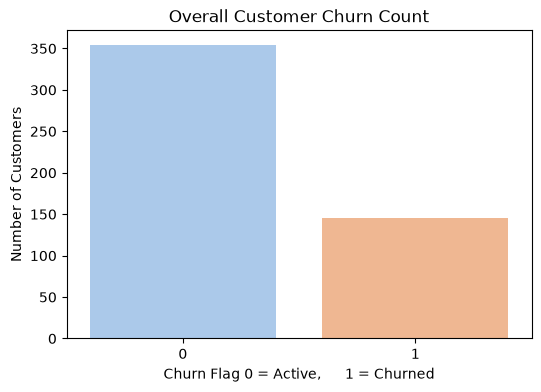

In [63]:
# count plot
# count of churn user and non churn user
plt.figure(figsize=(6, 4))
sns.countplot(data = df_visual, x='churn_flag', palette='pastel')
plt.title('Overall Customer Churn Count')
plt.xlabel('Churn Flag 0 = Active,      1 = Churned')
plt.ylabel('Number of Customers')
plt.show()

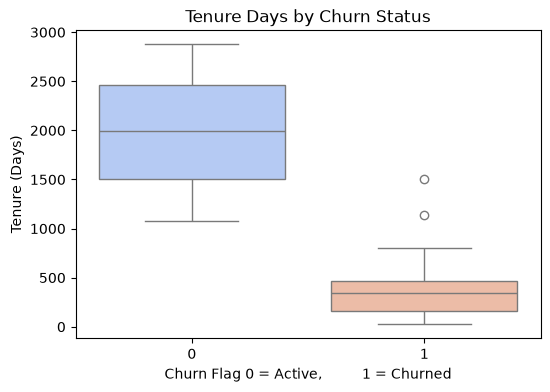

In [64]:
#  Box plot
# Tenure Days vs Churn Status
plt.figure(figsize=(6, 4))
sns.boxplot(data = df_visual, x='churn_flag', y='tenure_days', palette='coolwarm')
plt.title('Tenure Days by Churn Status')
plt.xlabel('Churn Flag 0 = Active,          1 = Churned')
plt.ylabel('Tenure (Days)')
plt.show()

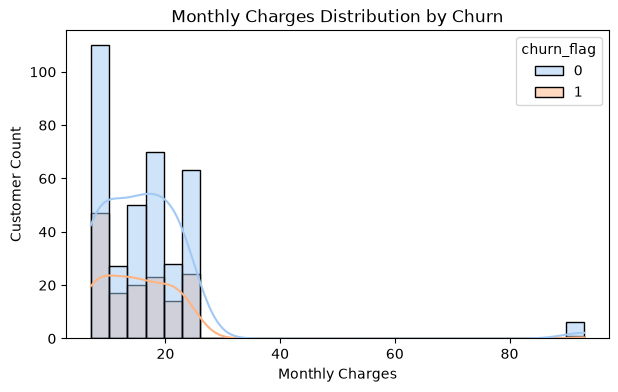

In [65]:
# Histogram chart
# Monthly charges distribution (active vs churned)
plt.figure(figsize=(7, 4))
sns.histplot(data = df_visual, x='monthly_charges', hue='churn_flag', kde=True, palette='pastel')
plt.title('Monthly Charges Distribution by Churn')
plt.xlabel('Monthly Charges')
plt.ylabel('Customer Count')
plt.show()

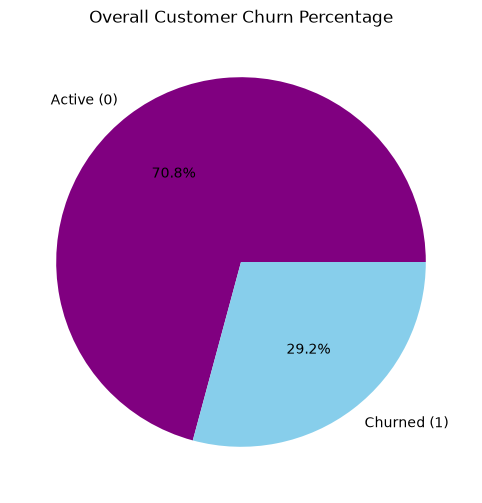

In [66]:
# Pie chart
# Overall churn percentage
plt.figure(figsize=(6, 6))
churn_counts = df_visual['churn_flag'].value_counts()
plt.pie(churn_counts, labels=['Active (0)', 'Churned (1)'], autopct='%1.1f%%', colors=["purple", "skyblue"])
plt.title('Overall Customer Churn Percentage')
plt.show()

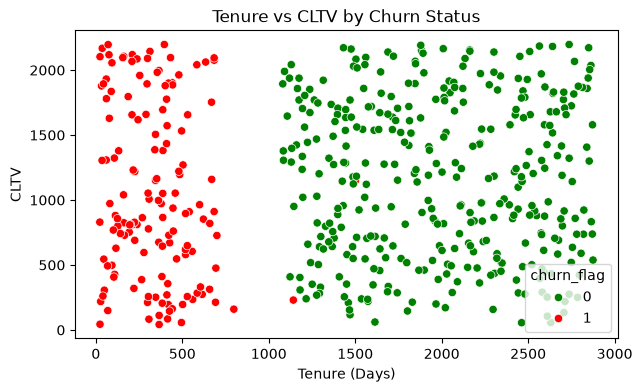

In [67]:
# Scatter plot
# Tenure vs CLTV (Active vs Churned)
plt.figure(figsize=(7, 4))
sns.scatterplot(data=df, x='tenure_days', y='cltv', hue='churn_flag', palette=['green', 'red'])
plt.title('Tenure vs CLTV by Churn Status')
plt.xlabel('Tenure (Days)')
plt.ylabel('CLTV')
plt.show()